# Determining the optimal candidate bounding-box size

This notebook reads the annotation CSV and visualises the **size distribution of the
existing candidate bounding boxes** so you can pick a sensible value for
`TARGET_BOX_SIZE_M` (the fixed, centroid-preserved box used by the ordering pipeline).

A good fixed crop should:
* cover e.g. the 90th-99th percentile of the *landslide* boxes so it rarely cuts a slide,
* be square (the ordering pipeline uses a square box of side `TARGET_BOX_SIZE_M`) that
  matches whichever axis (width/height) is longer at your chosen quantile.


### 1. Inputs & setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# <- point this at your annotation file
ANNOTATION_CSV = '/home/sanja/landslide_detection/landslide_detection/annotation.csv'
QUANTILES      = [0.50, 0.75, 0.90, 0.95, 0.99]

df = pd.read_csv(ANNOTATION_CSV)
df['label'] = df['label'].astype(str).str.strip().str.lower()
print('rows:', len(df), '| labels:', df['label'].value_counts().to_dict())

# Approximate ground size in metres (lon width scaled by cos(lat) for Nepal ~26-30N).
lat_c = (df['min_lat'] + df['max_lat']) / 2.0
df['width_m']  = (df['max_lon'] - df['min_lon']) * 111000.0 * np.cos(np.radians(lat_c))
df['height_m'] = (df['max_lat'] - df['min_lat']) * 111000.0
df['area_m2']  = df['width_m'] * df['height_m']
df['long_m']   = np.maximum(df['width_m'], df['height_m'])
df['short_m']  = np.minimum(df['width_m'], df['height_m'])
print(df[['width_m','height_m','area_m2','long_m','short_m']].describe().round(1).to_string())


rows: 6267 | labels: {'not_landslide': 6005, 'landslide': 262}
       width_m  height_m    area_m2  long_m  short_m
count   3381.0    3381.0     3381.0  3381.0   3381.0
mean     754.1     748.6   585237.5   800.9    701.8
std      188.5     172.9   383822.1   186.5    160.4
min      329.9     340.5   142829.5   390.7    329.9
25%      683.9     685.3   471905.4   712.4    663.2
50%      722.4     722.5   513642.4   749.8    693.9
75%      789.6     781.6   598194.9   821.8    741.0
max     3658.5    2763.7  7490160.5  3658.5   2559.0


### 2. Summary statistics by label

In [2]:
def summarize(g):
    return {
        'n': int(len(g)),
        'width p50/p90/p99 (m)': (round(g['width_m'].quantile(0.50)), round(g['width_m'].quantile(0.90)), round(g['width_m'].quantile(0.99))),
        'height p50/p90/p99 (m)': (round(g['height_m'].quantile(0.50)), round(g['height_m'].quantile(0.90)), round(g['height_m'].quantile(0.99))),
        'long side p50/p90/p99 (m)': (round(g['long_m'].quantile(0.50)), round(g['long_m'].quantile(0.90)), round(g['long_m'].quantile(0.99))),
        'area p50/p90/p99 (m2)': (round(g['area_m2'].quantile(0.50)), round(g['area_m2'].quantile(0.90)), round(g['area_m2'].quantile(0.99))),
    }

groups = {'all': df}
for l in df['label'].unique():
    groups[l] = df[df['label'] == l]
summary = pd.DataFrame({k: summarize(v) for k, v in groups.items()}).T
print(summary.to_string())


                  n width p50/p90/p99 (m) height p50/p90/p99 (m) long side p50/p90/p99 (m)      area p50/p90/p99 (m2)
all            6267      (722, 894, 1523)       (722, 891, 1420)          (750, 942, 1616)  (513642, 758912, 1822837)
not_landslide  6005      (722, 899, 1529)       (722, 891, 1469)          (750, 944, 1640)  (513426, 765683, 2007544)
landslide       262      (729, 833, 1110)       (720, 823, 1190)          (745, 853, 1218)  (522828, 678365, 1384217)


### 3. Area + length-vs-height plots

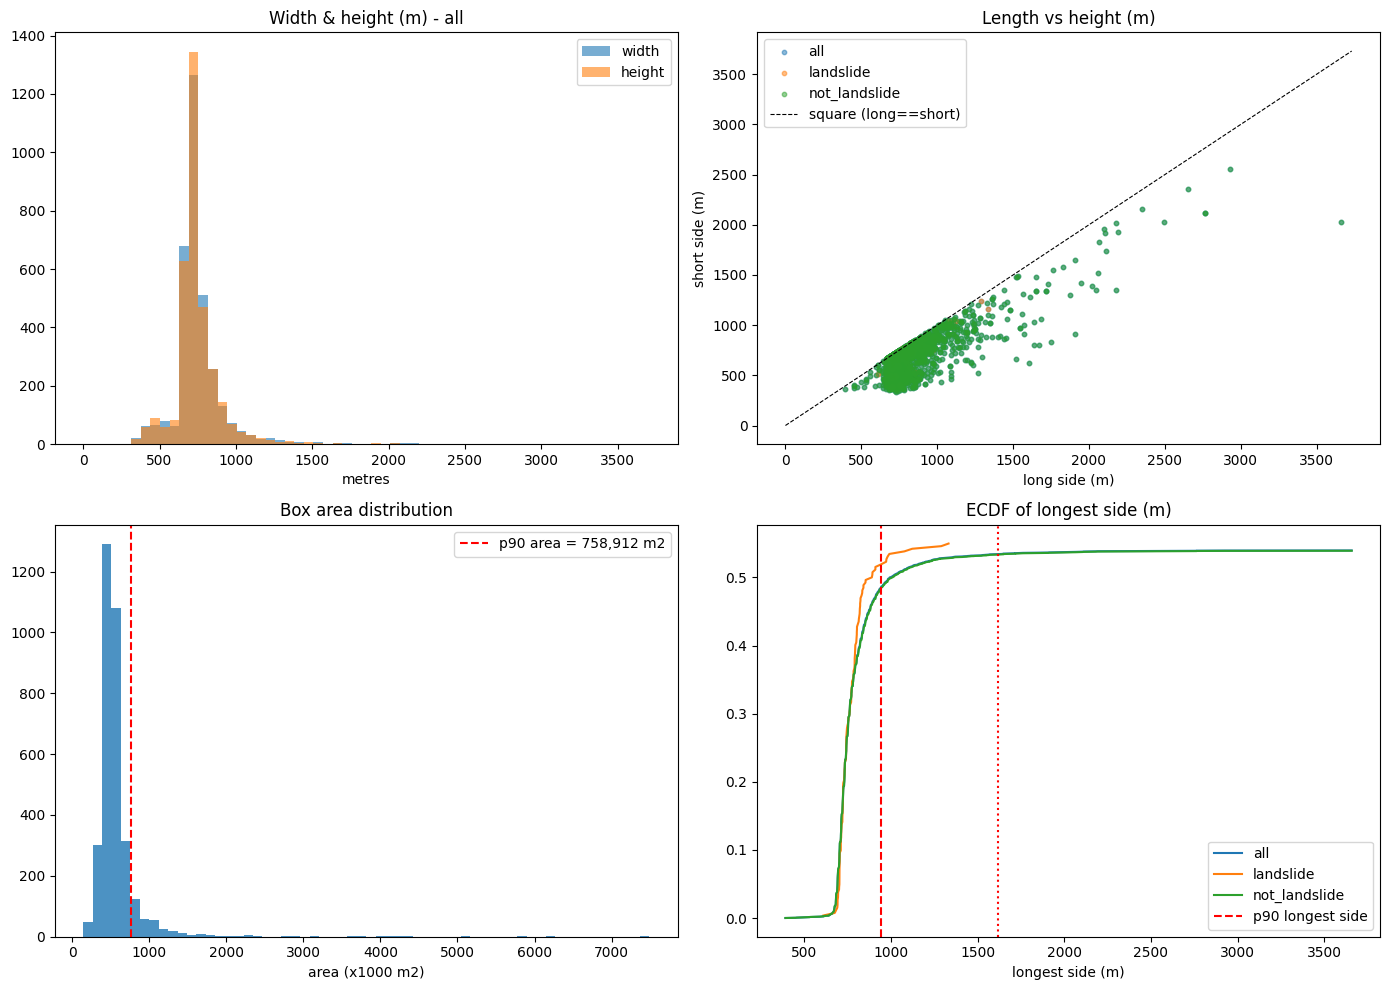

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
cmap = plt.colormaps['tab10']
labels = ['all'] + sorted(df['label'].unique())

# (a) Width & height histograms
bins = np.linspace(0, df[['width_m','height_m']].max().max() + 50, 60)
axes[0,0].hist(df['width_m'], bins=bins, alpha=0.6, label='width',  color=cmap(0))
axes[0,0].hist(df['height_m'], bins=bins, alpha=0.6, label='height', color=cmap(1))
axes[0,0].set_xlabel('metres'); axes[0,0].set_title('Width & height (m) - all')
axes[0,0].legend()

# (b) Length (long side) vs height (short side) scatter, by label
for i, l in enumerate(labels):
    m = (df['label'] == l) if l != 'all' else np.ones(len(df), dtype=bool)
    axes[0,1].scatter(df['long_m'][m], df['short_m'][m], s=10, alpha=0.5, label=l, color=cmap(i))
maxv = max(df['long_m'].max(), df['short_m'].max()) * 1.02
axes[0,1].plot([0, maxv], [0, maxv], 'k--', lw=0.8, label='square (long==short)')
axes[0,1].set_xlabel('long side (m)'); axes[0,1].set_ylabel('short side (m)')
axes[0,1].set_title('Length vs height (m)'); axes[0,1].legend()

# (c) Area histogram
axes[1,0].hist(df['area_m2'] / 1e3, bins=60, alpha=0.8)
p90 = df['area_m2'].quantile(0.9)
axes[1,0].axvline(p90 / 1e3, color='red', lw=1.5, ls='--', label=f'p90 area = {p90:,.0f} m2')
axes[1,0].set_xlabel('area (x1000 m2)'); axes[1,0].set_title('Box area distribution')
axes[1,0].legend()

# (d) ECDF of the longest side (best basis for choosing a square cut)
for i, l in enumerate(labels):
    m = (df['label'] == l) if l != 'all' else np.ones(len(df), dtype=bool)
    xx = np.sort(df['long_m'][m]); yy = np.arange(1, len(xx)+1) / len(xx)
    axes[1,1].plot(xx, yy, '-', color=cmap(i), label=l)
axes[1,1].axvline(df['long_m'].quantile(0.90), color='red', ls='--', label='p90 longest side')
axes[1,1].axvline(df['long_m'].quantile(0.99), color='red', ls=':')
axes[1,1].set_xlabel('longest side (m)'); axes[1,1].set_title('ECDF of longest side (m)')
axes[1,1].legend()

plt.tight_layout(); plt.show()


### 4. Suggested `TARGET_BOX_SIZE_M`

In [4]:
# Base the choice on the LONGEST side of landslide boxes so a fixed square crop
# never cuts a slide. Rounded up to the nearest 10 m for a usable constant.
use_df = df[df['label'] == 'landslide'] if (df['label'] == 'landslide').any() else df
side = use_df['long_m']
print('Basis: %d landslide boxes' % len(use_df))
for q in QUANTILES:
    side_m = side.quantile(q)
    print(f'  longest-side p{int(q*100):2d} = {side_m:7.0f} m  ->  TARGET_BOX_SIZE_M ~ {np.ceil(side_m/10)*10:.0f} m')
print()
print('Recommendation: use the p90-p99 of the landslide longest side, e.g. TARGET_BOX_SIZE_M =',
      int(np.ceil(side.quantile(0.90)/10)*10), 'to', int(np.ceil(side.quantile(0.99)/10)*10), 'm')


Basis: 262 landslide boxes
  longest-side p50 =     745 m  ->  TARGET_BOX_SIZE_M ~ 750 m
  longest-side p75 =     802 m  ->  TARGET_BOX_SIZE_M ~ 810 m
  longest-side p90 =     853 m  ->  TARGET_BOX_SIZE_M ~ 860 m
  longest-side p95 =     967 m  ->  TARGET_BOX_SIZE_M ~ 970 m
  longest-side p99 =    1218 m  ->  TARGET_BOX_SIZE_M ~ 1220 m

Recommendation: use the p90-p99 of the landslide longest side, e.g. TARGET_BOX_SIZE_M = 860 to 1220 m
